# Physics-Informed Neural Networks (PINN) u PyTorch-u

Primeri iz notebook-a **17_PINN.ipynb** (TensorFlow), prepisani u **PyTorch**.

| Lab | Problem | Implementacija |
|---|---|---|
| 1 | du/dt = cos(2πt), u(0) = 1 | PINN implementiran ručno, u čistom PyTorch-u |
| 2 | isti problem kao Lab 1 | biblioteka DeepXDE sa PyTorch backendom |
| 3 | Ojlerova greda, y'''' + 1 = 0 | ručno, u čistom PyTorch-u |
| 4 | Navije–Stoksove jednačine (tok između ploča) | ručno, u čistom PyTorch-u, sa analizom pojedinačnih delova gubitka |

## TensorFlow → PyTorch: šta je šta

| Operacija | TensorFlow (original) | PyTorch |
|---|---|---|
| mreža | `tf.keras.Sequential([Dense(32, 'tanh'), Dense(1)])` | `nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 1))` |
| „prati izvod po t“ | `tape.watch(t)` | `t.requires_grad_(True)` |
| izvod du/dt | `tape.gradient(u, t)` | `torch.autograd.grad(u, t, ..., create_graph=True)` |
| izvod gubitka po težinama | `tape.gradient(loss, NN.trainable_variables)` | `loss.backward()` |
| korak optimizera | `optm.apply_gradients(...)` | `optimizer.step()` (pre toga `optimizer.zero_grad()`) |

**`create_graph=True`** je ekvivalent dve ugnježdene trake u TensorFlow-u: gubitak sadrži izvod du/dt, pa PyTorch mora da zapamti kako je on nastao da bi kasnije mogao da izračuna i izvod gubitka po težinama.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Uređaj:', device)

Uređaj: cpu


In [2]:
def izvod(y, x):
    # Izvod izlaza y po ulazu x, preko automatske diferencijacije.
    # create_graph=True: omogućava diferenciranje samog izvoda (drugi izvod, trening).
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

---
# Lab 1: PINN napisan ručno

**Problem:**

$$\frac{du}{dt} = \cos(2\pi t), \qquad u(0) = 1, \qquad t \in [0, 2]$$

**Tačno rešenje** (služi samo za proveru na kraju):

$$u(t) = \frac{1}{2\pi}\sin(2\pi t) + 1$$

**Gubitak:**

$$\mathcal{L} = \underbrace{\frac{1}{n}\sum_i \left(\frac{dNN(t_i)}{dt} - \cos 2\pi t_i\right)^2}_{\text{da li kriva poštuje pravilo}} + \underbrace{\left(NN(0) - 1\right)^2}_{\text{da li kreće od 1}}$$

### 1.1 Mreža i optimizer

In [3]:
NN = nn.Sequential(
    nn.Linear(1, 32),   # ulaz: jedan broj t → 32 neurona
    nn.Tanh(),          # glatka aktivacija (ima lepe izvode, za razliku od ReLU)
    nn.Linear(32, 1)    # izlaz: jedan broj u
).to(device)

print(NN)

optm = torch.optim.Adam(NN.parameters(), lr=0.001)

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=1, bias=True)
)


### 1.2 Gubitak

1. Mreža za svako t daje vrednost u.
2. Automatskim diferenciranjem računa se izvod du/dt.
3. Izvod se poredi sa desnom stranom jednačine, cos(2πt); razlika je **rezidual**.
4. Proverava se početni uslov u(0) = 1.

In [4]:
def ode_system(t, net):
    t = t.clone().requires_grad_(True)          # = tape.watch(t)

    u = net(t)                                  # mreža crta krivu
    u_t = izvod(u, t)                           # du/dt (izvod po ULAZU)

    ode_loss = u_t - torch.cos(2 * np.pi * t)   # rezidual: koliko kriva krši pravilo

    t_0 = torch.zeros((1, 1), device=device)
    IC_loss = net(t_0) - 1.0                    # početni uslov: u(0) mora biti 1

    total_loss = torch.mean(ode_loss**2) + torch.mean(IC_loss**2)
    return total_loss

### 1.3 Trening

`train_t` su **kolokacione tačke**: 30 nasumičnih trenutaka između 0 i 2 u kojima se proverava jednačina. To **nisu merenja**: mreža nikada ne vidi prave vrednosti u.

0 1.5603200197219849


1000 0.3874303996562958


2000 0.13727082312107086


3000 0.021831028163433075


4000 0.0007302586454898119


5000 0.00018953207472804934


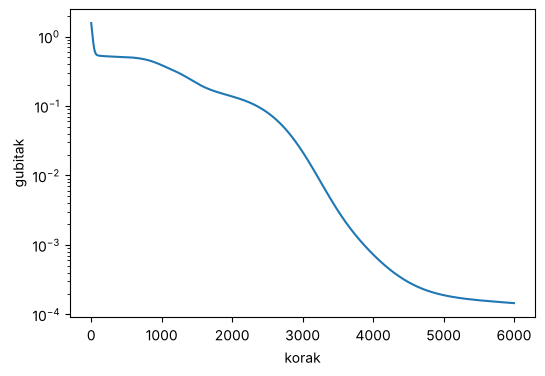

In [5]:
train_t = torch.rand(30, 1, device=device) * 2
train_loss_record = []

for itr in range(6000):
    optm.zero_grad()                       # brisanje gradijenata iz prethodnog koraka
    train_loss = ode_system(train_t, NN)   # računanje gubitka
    train_loss.backward()                  # izvod gubitka po TEŽINAMA (dL/dθ)
    optm.step()                            # ažuriranje težina

    train_loss_record.append(train_loss.item())
    if itr % 1000 == 0:
        print(itr, train_loss.item())

plt.figure(figsize=(6, 4))
plt.plot(train_loss_record)
plt.yscale('log')
plt.xlabel('korak')
plt.ylabel('gubitak')
plt.show()

### 1.4 Rezultat: PINN prema tačnom rešenju

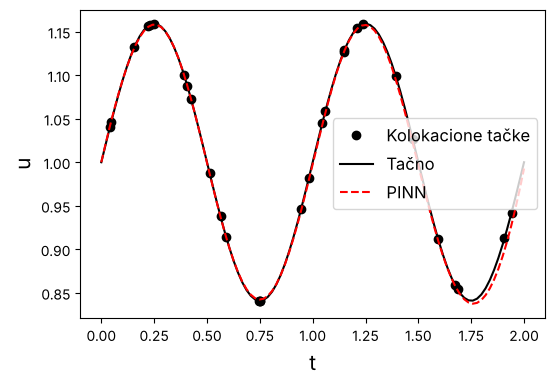

Najveća greška: 0.014103694377262443


In [6]:
test_t = np.linspace(0, 2, 100)
train_t_np = train_t.cpu().numpy()

train_u = np.sin(2*np.pi*train_t_np) / (2*np.pi) + 1   # samo za crtanje tačaka na pravoj krivoj
true_u = np.sin(2*np.pi*test_t) / (2*np.pi) + 1

with torch.no_grad():
    pred_u = NN(torch.tensor(test_t, dtype=torch.float32, device=device).reshape(-1, 1)).cpu().numpy().ravel()

plt.figure(figsize=(6, 4))
plt.plot(train_t_np, train_u, 'ok', label='Kolokacione tačke')
plt.plot(test_t, true_u, '-k', label='Tačno')
plt.plot(test_t, pred_u, '--r', label='PINN')
plt.legend(fontsize=12)
plt.xlabel('t', fontsize=15)
plt.ylabel('u', fontsize=15)
plt.show()

print('Najveća greška:', np.max(np.abs(pred_u - true_u)))

**Varijanta:** za jednačinu du/dt = −0,7·u (tačno rešenje e^(−0,7t)) u funkciji `ode_system` rezidual se menja u:

```python
ode_loss = u_t + 0.7 * u
```

a u ćeliji sa rezultatom tačno rešenje postaje `true_u = np.exp(-0.7 * test_t)`.

---
# Lab 2: isti problem preko DeepXDE (PyTorch backend)

DeepXDE automatski formira gubitak i petlju treninga; potrebno je samo opisati problem.

Backend se bira **pre prvog** `import deepxde`, preko promenljive okruženja `DDE_BACKEND`. Ako je DeepXDE u istoj sesiji već uvezen sa drugim backendom, potrebno je restartovati sesiju (Runtime → Restart session) i ponovo izvršiti ćelije, uključujući importe na vrhu.

| Lab 1 (ručno) | Lab 2 (DeepXDE) |
|---|---|
| `izvod(u, t)` | `dde.grad.jacobian(u, t)` |
| `IC_loss = net(t_0) - 1` | `dde.icbc.IC(geom, lambda t: 1, ...)` |
| `train_t` (30 tačaka) | `num_domain = 30` |
| `nn.Sequential(...)` | `dde.nn.FNN([1, 32, 1], 'tanh', ...)` |
| trening petlja | `model.train(iterations=6000)` |

In [7]:
!pip install -q deepxde

In [8]:
import os
os.environ['DDE_BACKEND'] = 'pytorch'

import deepxde as dde
print('DeepXDE backend:', dde.backend.backend_name)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


DeepXDE backend: pytorch


In [9]:
def ode_system_dde(t, u):
    du_t = dde.grad.jacobian(u, t)
    return du_t - torch.cos(2 * np.pi * t)

def initial(t, on_initial):
    return on_initial and np.isclose(t[0], 0)

def true_solution(t):
    return np.sin(2*np.pi*t) / (2*np.pi) + 1

geom = dde.geometry.TimeDomain(0, 2)
ic = dde.icbc.IC(geom, lambda t: 1, initial)

data = dde.data.PDE(geom,
                    ode_system_dde,
                    ic,
                    num_domain=30,
                    num_boundary=2,
                    solution=true_solution,
                    num_test=100)

net = dde.nn.FNN([1] + [32] + [1], 'tanh', 'Glorot uniform')

model = dde.Model(data, net)
model.compile('adam', lr=0.001, metrics=['l2 relative error'])

Compiling model...
'compile' took 0.000196 s



Training model...

Step      Train loss              Test loss               Test metric   


0         [6.10e-01, 1.00e+00]    [5.89e-01, 1.00e+00]    [1.34e+00]    


1000      [4.95e-01, 1.01e-05]    [4.90e-01, 1.01e-05]    [1.13e-01]    


2000      [3.24e-01, 9.91e-05]    [3.34e-01, 9.91e-05]    [9.38e-02]    


3000      [1.31e-01, 5.47e-07]    [1.42e-01, 5.47e-07]    [5.23e-02]    


4000      [1.89e-02, 1.16e-07]    [2.13e-02, 1.16e-07]    [1.55e-02]    


5000      [7.28e-03, 2.13e-08]    [6.26e-03, 2.13e-08]    [8.77e-03]    


6000      [4.74e-03, 6.28e-11]    [3.59e-03, 6.28e-11]    [6.00e-03]    



Best model at step 6000:
  train loss: 4.74e-03
  test loss: 3.59e-03
  test metric: [6.00e-03]

'train' took 6.772088 s



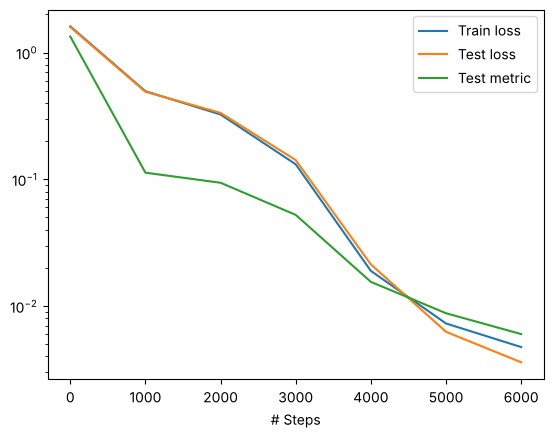

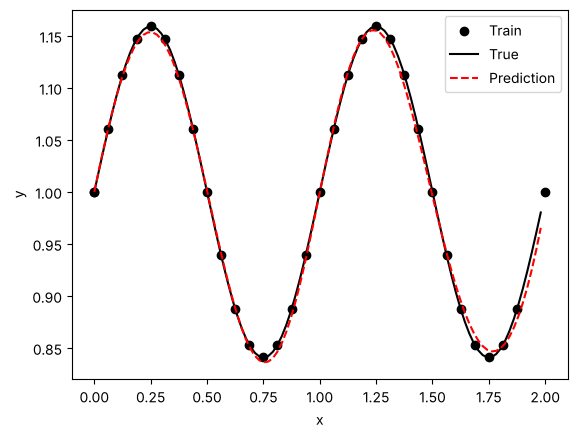

In [10]:
losshistory, train_state = model.train(iterations=6000)
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

---
# Lab 3: Ojlerova greda (savijanje grede)

**Jednačina** (greda dužine 1, pod ravnomernim opterećenjem):

$$\frac{d^4 y}{dx^4} + 1 = 0, \qquad x \in [0, 1]$$

**Granični uslovi:**

| uslov | značenje |
|---|---|
| y(0) = 0 | levi kraj je pričvršćen, ne pomera se |
| y'(0) = 0 | levi kraj je uklješten, ne naginje se |
| y''(1) = 0 | desni kraj je slobodan: nema momenta savijanja |
| y'''(1) = 0 | desni kraj je slobodan: nema sile smicanja |

**Tačno rešenje:**

$$y(x) = -\frac{x^4}{24} + \frac{x^3}{6} - \frac{x^2}{4}$$

Jedina novina u odnosu na Lab 1 su **viši izvodi**: funkcija `izvod` primenjuje se četiri puta zaredom.

Ovo je zapravo **ODE** (zavisi samo od x), iako se u originalu funkcija zove `pde`.

In [11]:
torch.manual_seed(0)

net_beam = nn.Sequential(
    nn.Linear(1, 20), nn.Tanh(),
    nn.Linear(20, 20), nn.Tanh(),
    nn.Linear(20, 20), nn.Tanh(),
    nn.Linear(20, 1)
).to(device)

optm_beam = torch.optim.Adam(net_beam.parameters(), lr=0.001)

x_domain = torch.rand(10, 1, device=device)   # 10 kolokacionih tačaka unutar grede (kao num_domain=10)
x_left = torch.zeros(1, 1, device=device)     # levi kraj, x = 0
x_right = torch.ones(1, 1, device=device)     # desni kraj, x = 1

def beam_loss(net):
    # 1) jednačina unutar grede
    x = x_domain.clone().requires_grad_(True)
    y = net(x)
    y_x = izvod(y, x)
    y_xx = izvod(y_x, x)
    y_xxx = izvod(y_xx, x)
    y_xxxx = izvod(y_xxx, x)
    pde = y_xxxx + 1

    # 2) levi kraj: y(0) = 0 i y'(0) = 0
    xl = x_left.clone().requires_grad_(True)
    yl = net(xl)
    yl_x = izvod(yl, xl)

    # 3) desni kraj: y''(1) = 0 i y'''(1) = 0
    xr = x_right.clone().requires_grad_(True)
    yr = net(xr)
    yr_xx = izvod(izvod(yr, xr), xr)
    yr_xxx = izvod(yr_xx, xr)

    return (torch.mean(pde**2)
            + torch.mean(yl**2) + torch.mean(yl_x**2)
            + torch.mean(yr_xx**2) + torch.mean(yr_xxx**2))

loss_record_beam = []
for itr in range(5000):
    optm_beam.zero_grad()
    loss = beam_loss(net_beam)
    loss.backward()
    optm_beam.step()
    loss_record_beam.append(loss.item())
    if itr % 1000 == 0:
        print(itr, loss.item())

0 0.8219344019889832


1000 0.00030927290208637714


2000 1.2483387763495557e-05


3000 2.9109719434927683e-06


4000 6.736354407621548e-06


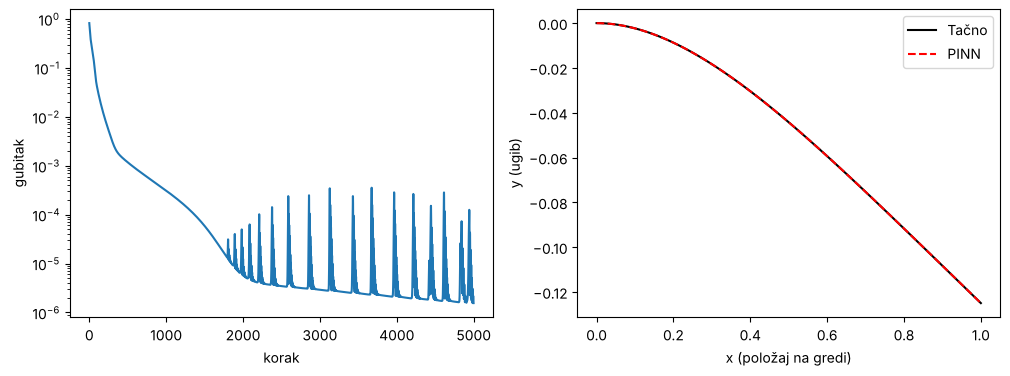

Relativna L2 greška: 0.00016262479424170715


In [12]:
x_test = np.linspace(0, 1, 100)
y_true = -(x_test**4)/24 + x_test**3/6 - x_test**2/4

with torch.no_grad():
    y_pred = net_beam(torch.tensor(x_test, dtype=torch.float32, device=device).reshape(-1, 1)).cpu().numpy().ravel()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(loss_record_beam)
ax[0].set_yscale('log')
ax[0].set_xlabel('korak')
ax[0].set_ylabel('gubitak')

ax[1].plot(x_test, y_true, '-k', label='Tačno')
ax[1].plot(x_test, y_pred, '--r', label='PINN')
ax[1].set_xlabel('x (položaj na gredi)')
ax[1].set_ylabel('y (ugib)')
ax[1].legend()
plt.show()

print('Relativna L2 greška:', np.linalg.norm(y_pred - y_true) / np.linalg.norm(y_true))

---
# Lab 4: Navije–Stoksove jednačine (tok između dve ploče)

Tečnost ulazi s leve strane ravnomernom brzinom, lepi se za zidove i postepeno formira **paraboličan profil**: najbrža je u sredini, a uz zidove stoji.

**Mreža:** ulaz (x, y), izlaz (u, v, p):
- u: brzina napred (pravac x)
- v: brzina gore-dole (pravac y)
- p: pritisak

**Tri jednačine** (sve tri treba da budu 0 u svakoj tački):

$$
\begin{aligned}
u\,u_x + v\,u_y + \tfrac{1}{\rho}p_x - \nu(u_{xx} + u_{yy}) &= 0 \quad\text{(kretanje napred)}\\
u\,v_x + v\,v_y + \tfrac{1}{\rho}p_y - \nu(v_{xx} + v_{yy}) &= 0 \quad\text{(kretanje gore-dole)}\\
u_x + v_y &= 0 \quad\text{(ništa ne nestaje)}
\end{aligned}
$$

**Šest graničnih uslova:**

| ivica | uslovi |
|---|---|
| zidovi (y = ±0,5) | u = 0, v = 0 |
| ulaz (x = −1) | u = 1, v = 0 |
| izlaz (x = 1) | p = 0, v = 0 |

### 4.1 Parametri

In [13]:
rho = 1      # gustina
mu = 1       # viskoznost
u_in = 1     # ulazna brzina
D = 1        # razmak između ploča
L = 2        # dužina kanala
nu = mu / rho

### 4.2 Tačke (kolokacione i granične)

- **2000 tačaka unutra**, gde se proveravaju jednačine. Biraju se Sobolovim nizom, koji tačke raspoređuje ravnomerno (kao Hammersley u DeepXDE-u).
- **200 tačaka na ivicama**: po 70 na svakom zidu, 30 na ulazu i 30 na izlazu.

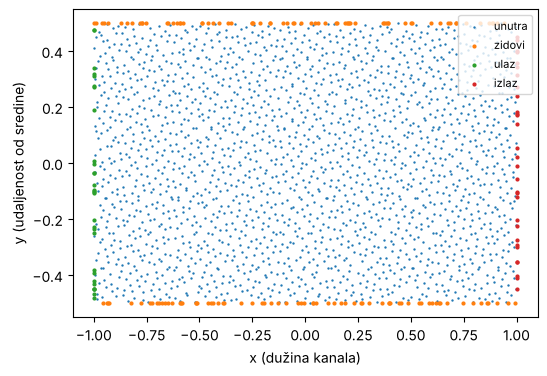

In [14]:
torch.manual_seed(0)

sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=0)
s = sobol.draw(2000)
X_domain = torch.stack([s[:, 0] * L - L/2, s[:, 1] * D - D/2], dim=1)

def tacke_na_liniji(n, x=None, y=None):
    # n tačaka na vertikalnoj liniji (zadato x) ili horizontalnoj liniji (zadato y)
    if x is not None:
        yy = torch.rand(n, 1) * D - D/2
        return torch.cat([torch.full((n, 1), float(x)), yy], dim=1)
    xx = torch.rand(n, 1) * L - L/2
    return torch.cat([xx, torch.full((n, 1), float(y))], dim=1)

X_wall = torch.cat([tacke_na_liniji(70, y=-D/2), tacke_na_liniji(70, y=D/2)])   # donji i gornji zid
X_inlet = tacke_na_liniji(30, x=-L/2)                                            # ulaz
X_outlet = tacke_na_liniji(30, x=L/2)                                            # izlaz

X_domain, X_wall, X_inlet, X_outlet = [t.to(device) for t in (X_domain, X_wall, X_inlet, X_outlet)]

plt.figure(figsize=(6, 4))
plt.scatter(X_domain[:, 0].cpu(), X_domain[:, 1].cpu(), s=0.5, label='unutra')
for X, lbl in [(X_wall, 'zidovi'), (X_inlet, 'ulaz'), (X_outlet, 'izlaz')]:
    plt.scatter(X[:, 0].cpu(), X[:, 1].cpu(), s=4, label=lbl)
plt.xlabel('x (dužina kanala)')
plt.ylabel('y (udaljenost od sredine)')
plt.legend(loc='upper right', fontsize=8)
plt.show()

### 4.3 Mreža i fizika

`izvod(u, X)` vraća **oba** prva izvoda odjednom, jer X ima dve kolone: kolona 0 je ∂u/∂x, a kolona 1 je ∂u/∂y. Drugi izvod se dobija ponovnim diferenciranjem jedne od tih kolona.

In [15]:
torch.manual_seed(0)

layers = [nn.Linear(2, 64), nn.Tanh()]
for _ in range(4):
    layers += [nn.Linear(64, 64), nn.Tanh()]
layers += [nn.Linear(64, 3)]
net_ns = nn.Sequential(*layers).to(device)   # 2 → 64×5 → 3

def pde(X):
    X = X.clone().requires_grad_(True)
    Y = net_ns(X)
    u, v, p = Y[:, 0:1], Y[:, 1:2], Y[:, 2:3]

    # prvi izvodi: [:, 0:1] je po x, [:, 1:2] je po y
    du = izvod(u, X); du_x, du_y = du[:, 0:1], du[:, 1:2]
    dv = izvod(v, X); dv_x, dv_y = dv[:, 0:1], dv[:, 1:2]
    dp = izvod(p, X); dp_x, dp_y = dp[:, 0:1], dp[:, 1:2]

    # drugi izvodi
    du_xx = izvod(du_x, X)[:, 0:1]
    du_yy = izvod(du_y, X)[:, 1:2]
    dv_xx = izvod(dv_x, X)[:, 0:1]
    dv_yy = izvod(dv_y, X)[:, 1:2]

    pde_u = u*du_x + v*du_y + 1/rho * dp_x - nu*(du_xx + du_yy)
    pde_v = u*dv_x + v*dv_y + 1/rho * dp_y - nu*(dv_xx + dv_yy)
    pde_cont = du_x + dv_y
    return pde_u, pde_v, pde_cont

def mse(a):
    return torch.mean(a**2)

def ukupan_gubitak():
    pde_u, pde_v, pde_cont = pde(X_domain)
    Yw, Yi, Yo = net_ns(X_wall), net_ns(X_inlet), net_ns(X_outlet)

    loss_pde = mse(pde_u) + mse(pde_v) + mse(pde_cont)          # L_G
    loss_bc = (mse(Yw[:, 0]) + mse(Yw[:, 1])                    # zidovi: u = 0, v = 0
               + mse(Yi[:, 0] - u_in) + mse(Yi[:, 1])           # ulaz:   u = 1, v = 0
               + mse(Yo[:, 2]) + mse(Yo[:, 1]))                 # izlaz:  p = 0, v = 0
    return loss_pde + loss_bc, loss_pde, loss_bc                # L_total = L_G + L_BC

### 4.4 Trening (Adam)

Na GPU-u ovo traje par minuta, a na CPU-u znatno duže.

     0  ukupno 1.0955e+00  fizika 9.5976e-04  ivice 1.0946e+00


  1000  ukupno 1.1346e-01  fizika 1.4646e-02  ivice 9.8811e-02


  2000  ukupno 8.6633e-02  fizika 9.0680e-03  ivice 7.7565e-02


  3000  ukupno 7.2886e-02  fizika 6.8729e-03  ivice 6.6013e-02


  4000  ukupno 8.1930e-02  fizika 2.1522e-02  ivice 6.0408e-02


  5000  ukupno 6.4306e-02  fizika 1.0615e-02  ivice 5.3691e-02


  6000  ukupno 5.9614e-02  fizika 9.7321e-03  ivice 4.9882e-02


  7000  ukupno 5.0997e-02  fizika 4.5334e-03  ivice 4.6464e-02


  8000  ukupno 5.1650e-02  fizika 5.3088e-03  ivice 4.6341e-02


  9000  ukupno 4.6750e-02  fizika 3.5563e-03  ivice 4.3193e-02


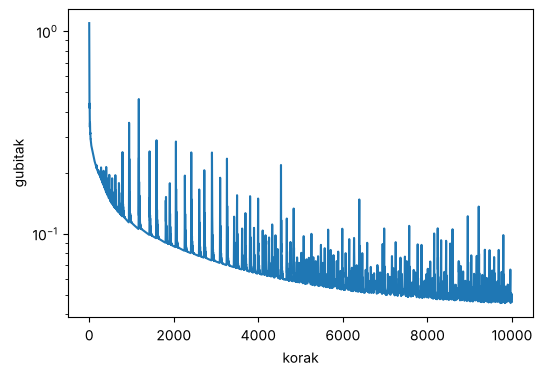

In [16]:
optm_ns = torch.optim.Adam(net_ns.parameters(), lr=1e-3)
loss_record_ns = []

for itr in range(10000):
    optm_ns.zero_grad()
    loss, loss_pde, loss_bc = ukupan_gubitak()
    loss.backward()
    optm_ns.step()
    loss_record_ns.append(loss.item())
    if itr % 1000 == 0:
        print(f'{itr:6d}  ukupno {loss.item():.4e}  fizika {loss_pde.item():.4e}  ivice {loss_bc.item():.4e}')

plt.figure(figsize=(6, 4))
plt.plot(loss_record_ns)
plt.yscale('log')
plt.xlabel('korak')
plt.ylabel('gubitak')
plt.show()

### 4.5 Rezultati posle Adama (u, v, p odozgo)

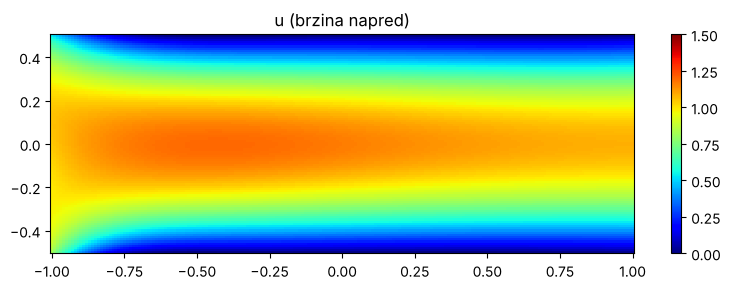

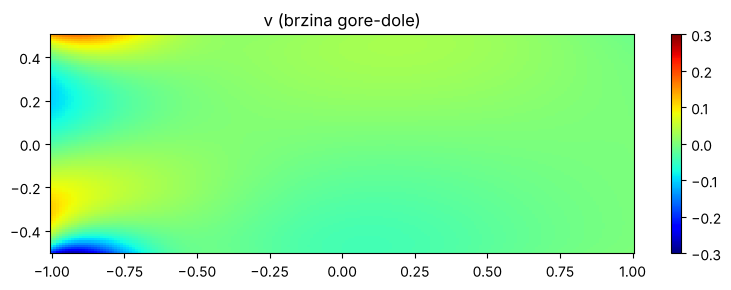

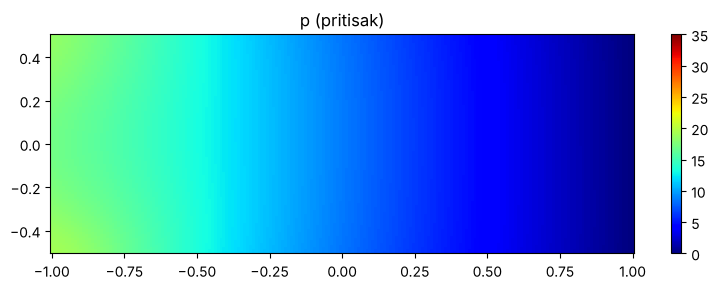

In [17]:
def nacrtaj_polja():
    nx, ny = 200, 100
    xs = np.linspace(-L/2, L/2, nx)
    ys = np.linspace(-D/2, D/2, ny)
    XX, YY = np.meshgrid(xs, ys)
    pts = torch.tensor(np.stack([XX.ravel(), YY.ravel()], axis=1), dtype=torch.float32, device=device)
    with torch.no_grad():
        res = net_ns(pts).cpu().numpy()

    imena = ['u (brzina napred)', 'v (brzina gore-dole)', 'p (pritisak)']
    color_legend = [[0, 1.5], [-0.3, 0.3], [0, 35]]
    for idx in range(3):
        plt.figure(figsize=(8, 3))
        plt.pcolormesh(XX, YY, res[:, idx].reshape(ny, nx), cmap='jet', shading='auto',
                       vmin=color_legend[idx][0], vmax=color_legend[idx][1])
        plt.colorbar()
        plt.title(imena[idx])
        plt.tight_layout()
        plt.show()

nacrtaj_polja()

### 4.6 Dodatni trening (L-BFGS)

L-BFGS je precizniji optimizer za fino doterivanje na kraju. Za razliku od Adama, on više puta zove funkciju gubitka u jednom koraku, pa mu se gubitak predaje kao funkcija (`closure`).

In [18]:
optm_lbfgs = torch.optim.LBFGS(net_ns.parameters(), lr=1.0, max_iter=3000,
                               tolerance_grad=1e-9, tolerance_change=1e-12,
                               history_size=50, line_search_fn='strong_wolfe')

def closure():
    optm_lbfgs.zero_grad()
    loss, _, _ = ukupan_gubitak()
    loss.backward()
    return loss

optm_lbfgs.step(closure)

loss, loss_pde, loss_bc = ukupan_gubitak()
print(f'Posle L-BFGS: ukupno {loss.item():.4e}  fizika {loss_pde.item():.4e}  ivice {loss_bc.item():.4e}')

Posle L-BFGS: ukupno 1.1103e-02  fizika 2.3541e-03  ivice 8.7492e-03


### 4.7 Rezultati posle Adam + L-BFGS

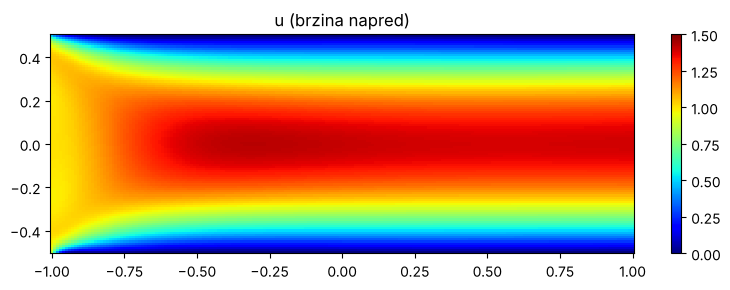

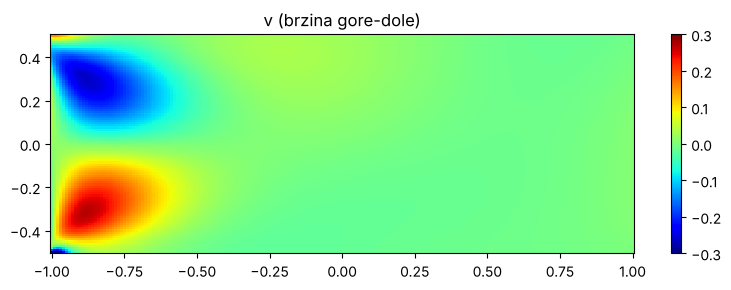

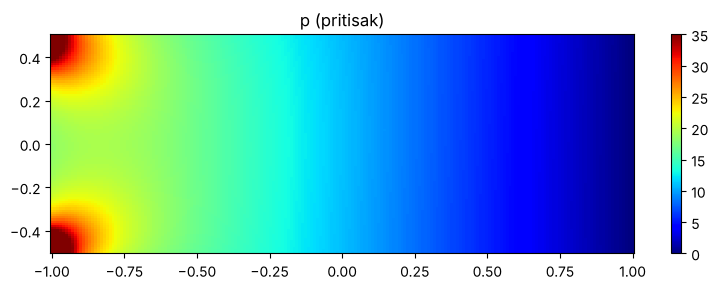

In [19]:
nacrtaj_polja()

### 4.8 Provera: profil brzine na izlazu

Za potpuno razvijen tok između ploča tačan profil je parabola:

$$u(y) = \frac{3}{2}\,u_{in}\left[1 - \left(\frac{y}{D/2}\right)^2\right]$$

U sredini (y = 0) brzina je 1,5, a uz zidove 0.

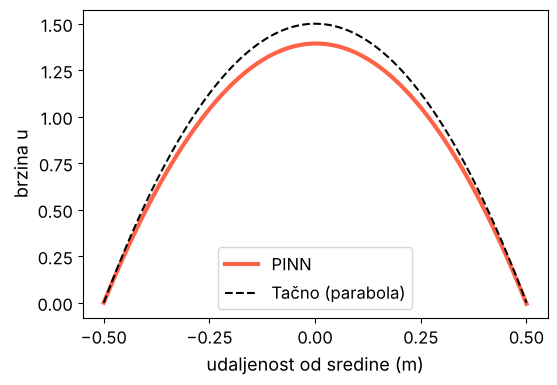

Brzina u sredini (PINN): 1.3934866  tačno: 1.5


In [20]:
y = np.linspace(-0.5, 0.5, 1000).reshape(-1, 1)
x = np.ones_like(y) * (L/2)
outlet = torch.tensor(np.hstack([x, y]), dtype=torch.float32, device=device)

analytic_solution = u_in * 1.5 * (1 - (y / (D/2))**2)
with torch.no_grad():
    PINN_solution = net_ns(outlet).cpu().numpy()

plt.figure(figsize=(6, 4))
plt.plot(y, PINN_solution[:, 0], c='tomato', linewidth=3, label='PINN')
plt.plot(y, analytic_solution, c='k', linestyle='--', label='Tačno (parabola)')
plt.xticks(np.linspace(-0.5, 0.5, 5), fontsize=12)
plt.yticks(np.linspace(0, 1.5, 7), fontsize=12)
plt.legend(fontsize=12)
plt.xlabel('udaljenost od sredine (m)', fontsize=13)
plt.ylabel('brzina u', fontsize=13)
plt.show()

print('Brzina u sredini (PINN):', PINN_solution[500, 0], ' tačno: 1.5')

---
### 4.9 Gubitak po delovima: koliko koji granični uslov utiče

Ukupni gubitak je zbir 9 delova: 3 reziduala jednačina (fizika) i 6 graničnih uslova. Mreža se ovde trenira ponovo od početka (Adam, pa L-BFGS), uz praćenje **svakog dela posebno**, kako bi se videlo koji su uslovi najteži za ispunjavanje i kako na njih utiče L-BFGS.

In [ ]:
def gubici_po_delovima():
    pde_u, pde_v, pde_cont = pde(X_domain)
    Yw, Yi, Yo = net_ns(X_wall), net_ns(X_inlet), net_ns(X_outlet)
    return {
        'fizika: kretanje x': mse(pde_u),
        'fizika: kretanje y': mse(pde_v),
        'fizika: kontinuitet': mse(pde_cont),
        'zid: u = 0': mse(Yw[:, 0]),
        'zid: v = 0': mse(Yw[:, 1]),
        'ulaz: u = 1': mse(Yi[:, 0] - u_in),
        'ulaz: v = 0': mse(Yi[:, 1]),
        'izlaz: p = 0': mse(Yo[:, 2]),
        'izlaz: v = 0': mse(Yo[:, 1]),
    }

FIZIKA = ['fizika: kretanje x', 'fizika: kretanje y', 'fizika: kontinuitet']
IVICE = ['zid: u = 0', 'zid: v = 0', 'ulaz: u = 1', 'ulaz: v = 0', 'izlaz: p = 0', 'izlaz: v = 0']
istorija = {k: [] for k in FIZIKA + IVICE}
koraci = []          # redni broj zapisa (Adam koraci, pa L-BFGS izračunavanja)

def zapamti(d, n):
    for k, v in d.items():
        istorija[k].append(v.item())
    koraci.append(n)

In [1]:
torch.manual_seed(0)
layers = [nn.Linear(2, 64), nn.Tanh()]
for _ in range(4):
    layers += [nn.Linear(64, 64), nn.Tanh()]
layers += [nn.Linear(64, 3)]
net_ns = nn.Sequential(*layers).to(device)      # nova mreža, ista arhitektura kao gore

N_ADAM = 10000
ZAPIS = 10                                      # zapis svakog 10. koraka
optm_ns = torch.optim.Adam(net_ns.parameters(), lr=1e-3)

for itr in range(N_ADAM):
    optm_ns.zero_grad()
    d = gubici_po_delovima()
    loss = sum(d.values())
    loss.backward()
    optm_ns.step()
    if itr % ZAPIS == 0:
        zapamti(d, itr)
    if itr % 1000 == 0:
        fiz = sum(d[k].item() for k in FIZIKA); ivi = sum(d[k].item() for k in IVICE)
        print(f'{itr:6d}  ukupno {loss.item():.3e}  fizika {fiz:.3e}  ivice {ivi:.3e}')

posle_adama = {k: v.item() for k, v in gubici_po_delovima().items()}
n_adam_zapisa = len(koraci)

     0  ukupno 1.096e+00  fizika 9.598e-04  ivice 1.095e+00
  1000  ukupno 1.135e-01  fizika 1.465e-02  ivice 9.881e-02
  2000  ukupno 8.663e-02  fizika 9.068e-03  ivice 7.757e-02
  3000  ukupno 7.289e-02  fizika 6.873e-03  ivice 6.601e-02
  4000  ukupno 8.193e-02  fizika 2.152e-02  ivice 6.041e-02
  5000  ukupno 6.431e-02  fizika 1.061e-02  ivice 5.369e-02
  6000  ukupno 5.961e-02  fizika 9.732e-03  ivice 4.988e-02
  7000  ukupno 5.100e-02  fizika 4.533e-03  ivice 4.646e-02
  8000  ukupno 5.165e-02  fizika 5.309e-03  ivice 4.634e-02
  9000  ukupno 4.675e-02  fizika 3.556e-03  ivice 4.319e-02


In [2]:
optm_lbfgs = torch.optim.LBFGS(net_ns.parameters(), lr=1.0, max_iter=3000,
                               tolerance_grad=1e-9, tolerance_change=1e-12,
                               history_size=50, line_search_fn='strong_wolfe')
broj_eval = [0]

def closure():
    optm_lbfgs.zero_grad()
    d = gubici_po_delovima()
    loss = sum(d.values())
    loss.backward()
    if broj_eval[0] % ZAPIS == 0:
        zapamti(d, N_ADAM + broj_eval[0])
    broj_eval[0] += 1
    return loss

optm_lbfgs.step(closure)
posle_lbfgs = {k: v.item() for k, v in gubici_po_delovima().items()}
print('L-BFGS izračunavanja gubitka:', broj_eval[0])

L-BFGS izračunavanja gubitka: 3163


In [3]:
def zbir(d, kljucevi): return sum(d[k] for k in kljucevi)
uk_a, uk_l = zbir(posle_adama, FIZIKA + IVICE), zbir(posle_lbfgs, FIZIKA + IVICE)

print(f"{'deo gubitka':24s} {'posle Adama':>12s} {'udeo':>7s} {'posle L-BFGS':>13s} {'udeo':>7s} {'smanjenje':>10s}")
for k in FIZIKA + IVICE:
    a, l = posle_adama[k], posle_lbfgs[k]
    print(f'{k:24s} {a:12.2e} {a/uk_a:7.1%} {l:13.2e} {l/uk_l:7.1%} {a/l:9.1f}x')
print('-' * 80)
for ime, kl in [('UKUPNO fizika', FIZIKA), ('UKUPNO ivice', IVICE), ('UKUPNO', FIZIKA + IVICE)]:
    a, l = zbir(posle_adama, kl), zbir(posle_lbfgs, kl)
    print(f'{ime:24s} {a:12.2e} {a/uk_a:7.1%} {l:13.2e} {l/uk_l:7.1%} {a/l:9.1f}x')

deo gubitka               posle Adama    udeo  posle L-BFGS    udeo  smanjenje
fizika: kretanje x           8.68e-04    1.9%      7.28e-04    6.6%       1.2x
fizika: kretanje y           5.83e-04    1.3%      5.30e-04    4.8%       1.1x
fizika: kontinuitet          2.63e-03    5.7%      9.87e-04    9.0%       2.7x
zid: u = 0                   1.88e-02   40.7%      3.97e-03   36.2%       4.7x
zid: v = 0                   4.95e-03   10.7%      1.29e-03   11.8%       3.8x
ulaz: u = 1                  1.35e-02   29.3%      2.76e-03   25.2%       4.9x
ulaz: v = 0                  4.65e-03   10.1%      6.36e-04    5.8%       7.3x
izlaz: p = 0                 1.49e-04    0.3%      3.44e-05    0.3%       4.3x
izlaz: v = 0                 5.94e-06    0.0%      1.58e-05    0.1%       0.4x
--------------------------------------------------------------------------------
UKUPNO fizika                4.08e-03    8.9%      2.24e-03   20.5%       1.8x
UKUPNO ivice                 4.21e-02   91.1%     

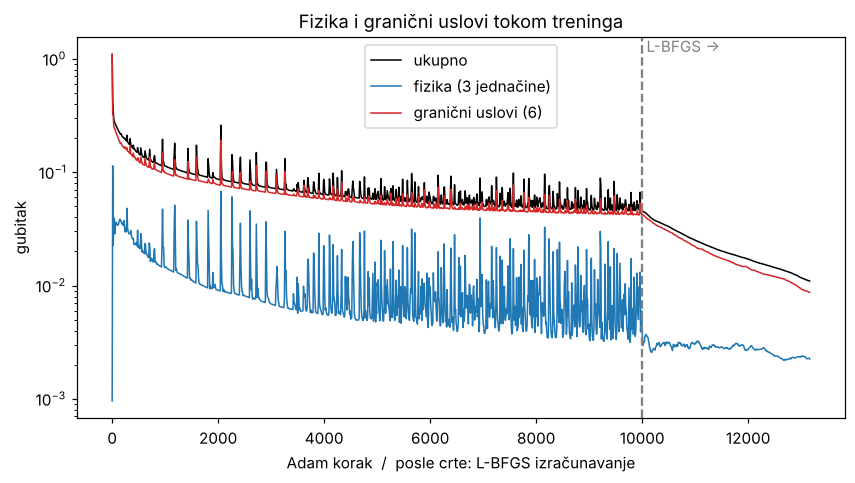

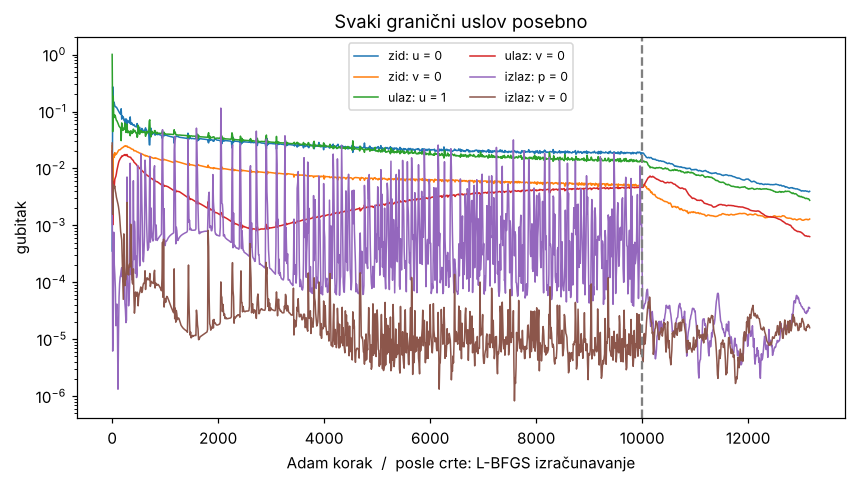

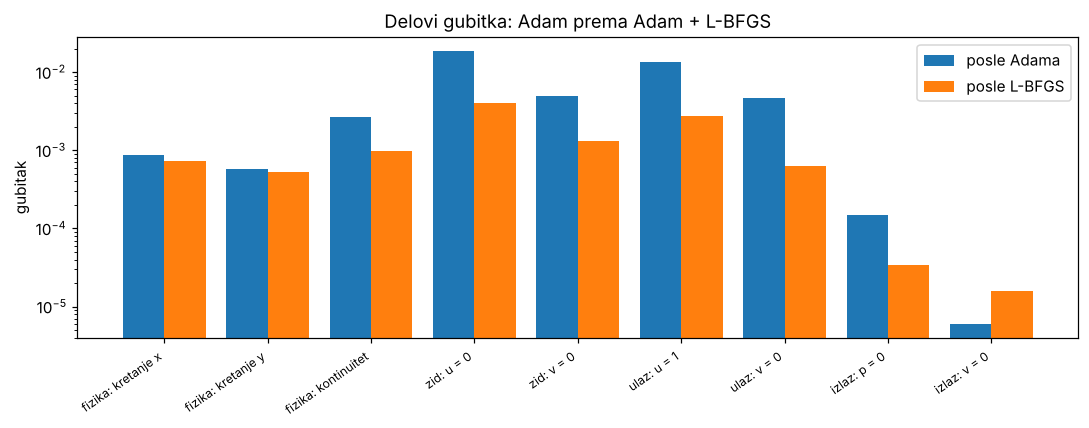

In [4]:
x = np.array(koraci)
granica = N_ADAM

fig, ax = plt.subplots(figsize=(9, 4.5))
fiz = np.sum([istorija[k] for k in FIZIKA], axis=0)
ivi = np.sum([istorija[k] for k in IVICE], axis=0)
ax.semilogy(x, fiz + ivi, color='black', lw=1, label='ukupno')
ax.semilogy(x, fiz, color='tab:blue', lw=1, label='fizika (3 jednačine)')
ax.semilogy(x, ivi, color='tab:red', lw=1, label='granični uslovi (6)')
ax.axvline(granica, color='gray', ls='--')
ax.set_xlabel('Adam korak  /  posle crte: L-BFGS izračunavanje')
ax.set_ylabel('gubitak'); ax.legend(); ax.set_title('Fizika i granični uslovi tokom treninga')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
for k in IVICE:
    ax.semilogy(x, istorija[k], lw=1, label=k)
ax.axvline(granica, color='gray', ls='--')
ax.set_xlabel('Adam korak  /  posle crte: L-BFGS izračunavanje')
ax.set_ylabel('gubitak'); ax.legend(fontsize=8, ncol=2); ax.set_title('Svaki granični uslov posebno')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
imena = FIZIKA + IVICE
pos = np.arange(len(imena))
ax.bar(pos - 0.2, [posle_adama[k] for k in imena], 0.4, label='posle Adama')
ax.bar(pos + 0.2, [posle_lbfgs[k] for k in imena], 0.4, label='posle L-BFGS')
ax.set_yscale('log'); ax.set_xticks(pos); ax.set_xticklabels(imena, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('gubitak'); ax.legend(); ax.set_title('Delovi gubitka: Adam prema Adam + L-BFGS')
plt.tight_layout(); plt.show()

**Zaključci:**

| | posle Adama | posle L-BFGS |
|---|---|---|
| ukupni gubitak | 4,6·10⁻² | 1,1·10⁻² (4,2× manje) |
| udeo graničnih uslova | **91 %** | **80 %** |
| udeo fizike | 9 % | 20 % |

- **Gubitak dominantno potiče od graničnih uslova**, i to od dva: *zid u = 0* (41 % posle Adama, 36 % posle L-BFGS) i *ulaz u = 1* (29 %, odnosno 25 %). To su upravo uslovi koji se sudaraju u uglovima kod ulaza (x = −1, y = ±0,5), gde bi brzina istovremeno trebalo da bude 0 i 1, pa ih mreža ne može ispuniti oba.
- **Uslovi na izlazu** (p = 0, v = 0) su gotovo savršeno ispunjeni (ispod 0,3 % gubitka).
- **L-BFGS** najviše smanjuje gubitak graničnih uslova (4,8×), a fizike znatno manje (1,8×). Zato udeo fizike raste sa 9 % na 20 %.
- **Šiljci tokom Adama** se istovremeno javljaju u fizici i u graničnim uslovima: Adam napravi prevelik korak, pa se svi delovi gubitka na trenutak pogoršaju. Relativno najveće skokove ima *izlaz: p = 0*, koji iskače i za dva reda veličine. Posle prelaska na L-BFGS šiljaka više nema.